### Effect of a structured microbiome on the optimal immune repertoire

In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from matplotlib import patheffects
import scipy.optimize
from scipy.optimize import minimize, LinearConstraint, Bounds, NonlinearConstraint, linprog
from math import erf
import multiprocessing as mp
# from tqdm import tqdm
from joblib import Parallel, delayed
import itertools
import os
import random
import pandas as pd
import time
import plotly.graph_objects as go

sm = cm.ScalarMappable(norm = mcolors.Normalize(vmin=0.0, vmax=1.0), 
                           cmap=mpl.colormaps.get_cmap('Blues'))
cmap = plt.get_cmap('tab20c')
plt.style.use('/Users/ObinnaUkogu/Desktop/custom.mplstyle')
%config InlineBackend.figure_format = 'retina'

In [2]:
# Define parameters
m, k = 20, 80 # (num_microbes, num_receptors)
n = np.ones(1) # Niche supply
h = np.ones(1) # harm per microbe of microbe
Sigma = np.ones(1)
beta = 1.0
tol=1e-6
# day0_abundance_data = pd.read_csv('./data/wang_tableS2.csv')
# hCom1 = day0_abundance_data.day0_abundance[~np.isnan(day0_abundance_data.day0_abundance)]/100
kwargs = {'linewidth': 2.5, 'markeredgewidth': 0.25, 'markeredgecolor': 'k', 'markersize': 6}

In [3]:
# Define functions
def G(l, sigma = 1, n = n): # Microbe steady state population
    out = n/(1 + np.sum(l*sigma))
    return out

def objective(l, beta = 1.0, Sigma = np.eye(m), h = np.ones(m), n = np.ones(m),  b = np.ones(m)): # Cost function
    # beta := Cost of immune pressure

    out = np.sum([h[i]*G(l, sigma, n[i]) for i, sigma in enumerate(Sigma)]) + np.sum(beta*l) + np.sum(Sigma.dot(l)*np.array([b[i]*G(l, sigma, n[i]) for i, sigma in enumerate(Sigma)]))

    return out.item()

def limited_ecology(C, beta = 1.0, sigma = 1.0, h = np.ones(2), n = np.ones(2),  s = 1.0): # Cost function
    # beta := Cost of immune pressure

    out = h[0]*n[0]/(1 + C) + h[1]*n[1]/(1 + C + s*n[0]/(1 + C)) + beta*C

    return out.item()

# Define analytic solution
def single_receptor(beta, sigma = 1, h = 1.0, n = 1.0):
    if sigma/beta < n*h:
        out = 1/np.sqrt(sigma)*(np.sqrt(n*h/beta) - 1/np.sqrt(sigma))
    else:
        out = 0.0

    return out

## Simplest case: one microbe, one receptor

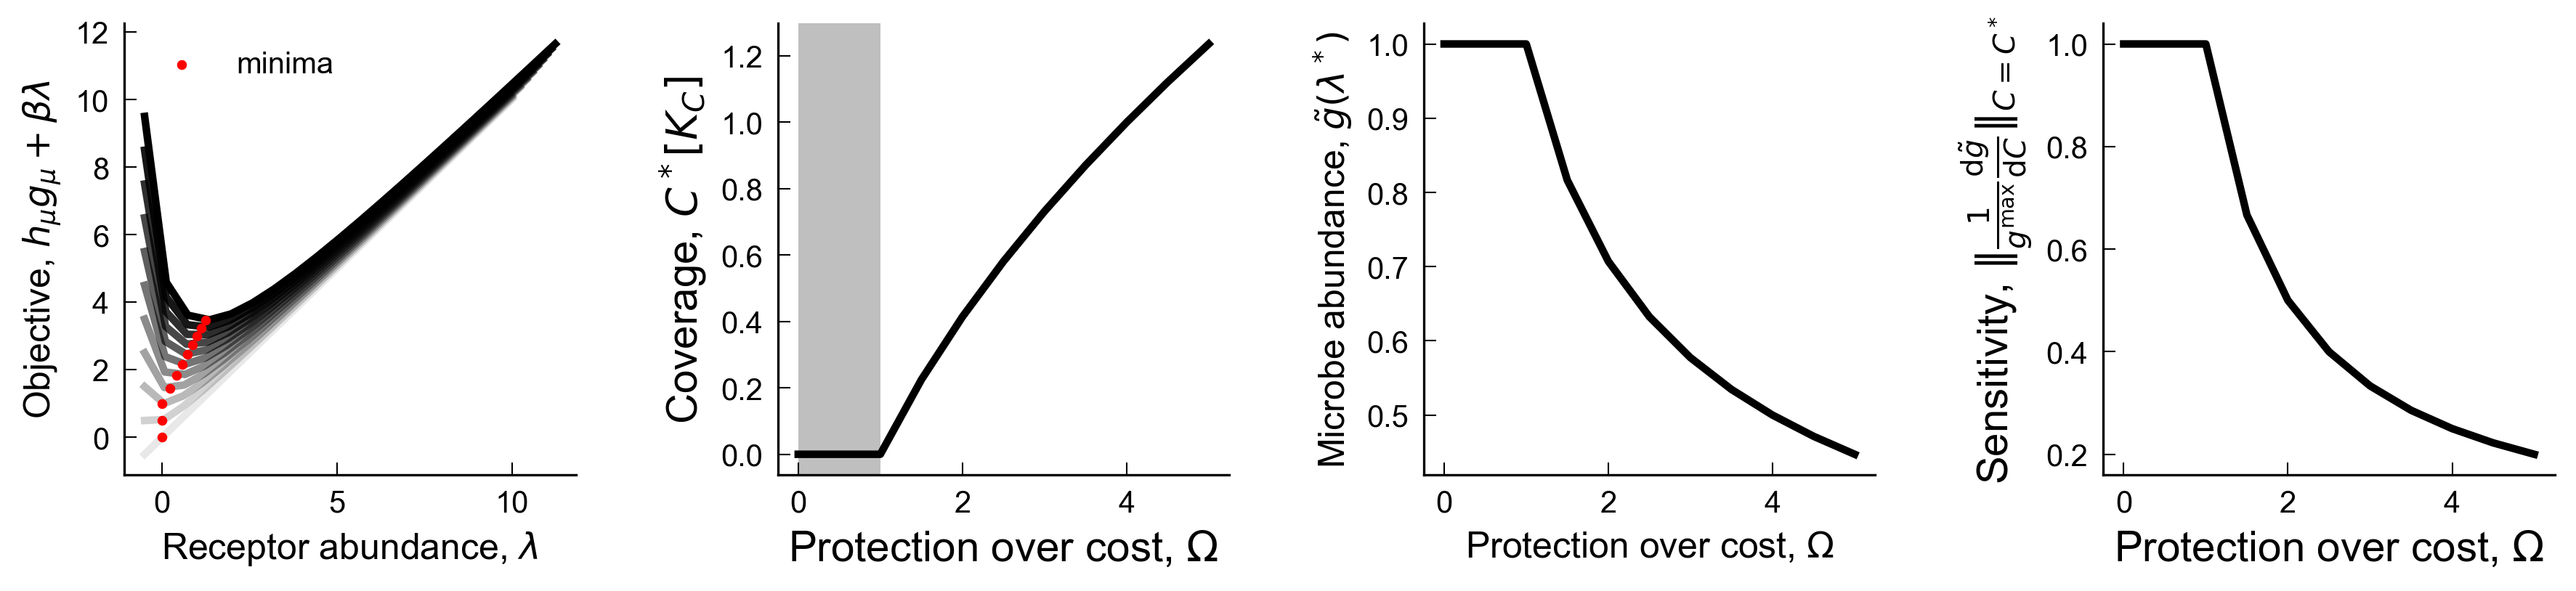

In [4]:
# Plot numerical values and analytic values verus beta
fig, (ax1, ax2, ax3, ax4) = plt.subplots(1, 4, dpi = 150, figsize=(12, 2.60), layout='constrained')

sigma = np.ones(1)
hs = np.linspace(0, 5, 11)
for i, p in enumerate(hs):

    res = minimize(objective, args = (1.0, np.array(sigma), np.array([p]), np.ones(1), np.zeros(1)),
                 x0 = [0.1],
                 tol=tol,
                 constraints = LinearConstraint([1.0], 0.0, np.inf))

    # ax1.scatter(p, res.x, c= 'black', label = "numeric" if i == 0 else '')
    ls = np.linspace(-0.5, res.x + 10, 20)

    ax1.plot(ls, np.array([objective(j, 1.0, sigma, np.array([p]), n, np.zeros(1)) for j in ls]), 'k', alpha = (i + 1)/len(hs), **kwargs)
    ax1.scatter(res.x, res.fun, color = 'red', s = 5, zorder = 2, label = "minima" if i == 0 else '')

l_opts = np.array([single_receptor(n=j, beta = 1.0) for j in hs])
ax2.plot(hs, l_opts, color = 'black',label = "analytic", **kwargs)
ax2.axvspan(0, 1, color = 'grey', zorder = 0, alpha = 0.5,linewidth=0)
#ax1.title.set_text(r'one microbe, one receptor')

ax3.plot(hs, 1/(1 + sigma*l_opts), color = 'black',label = "analytic", **kwargs)

ax4.plot(hs, np.abs(-1/(1 + sigma*l_opts)**2), color = 'black',label = "analytic", **kwargs)

ax1.set(xlabel=r'Receptor abundance, $\lambda$',ylabel=r'Objective, $h_\mu g_\mu + \beta \lambda$')
ax1.legend()
ax1.minorticks_off()
ax1.set_box_aspect(1)

ax2.set_xlabel(r'Protection over cost, $\Omega$', fontsize = 14)
ax2.set_ylabel(r'Coverage, $C^* [K_C]$', fontsize = 14)
ax2.minorticks_off()
ax2.set_box_aspect(1)

ax3.set(ylabel=r'Microbe abundance, $\tilde{g}(\lambda^*)$', xlabel=r'Protection over cost, $\Omega$')
ax3.minorticks_off()
ax3.set_box_aspect(1)

ax4.set_xlabel(r'Protection over cost, $\Omega$', fontsize = 14)
ax4.set_ylabel(r'Sensitivity, $\|\frac{1}{g^\text{max}}\frac{{\rm d}\tilde{g}}{{\rm d}C}\|_{C = C^*}$', fontsize = 14)
ax4.minorticks_off()
ax4.set_box_aspect(1)

for ax in (ax1, ax2, ax3, ax4):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(top=False, right=False)

fig.savefig('_figs/fig4_SIfig5_one_microbe_one_receptor'+'.pdf', dpi=300, bbox_inches='tight')

(A) The objective as a function of receptor abundance $\lambda$. Intensity of colored lines corresponds to the magnitude of the harm-cost ratio, $hg^\text{max}\beta^{-1}$. When this ratio is low, no receptors are deployed.

(B) Figure 4: Receptor abundance as a function of immune protection-to-cost ratio $\sigma hg^\text{max}\beta^{-1}$. A receptor will not be used unless it can cost-efficiently control the microbial population, $\sigma hg^\text{max}\beta^{-1} > 1$.

(C) Microbe abundance as a function of immune protection-to-cost ratio $\sigma hg^\text{max}\beta^{-1}$.

(D) SI Figure 5: Sensitivity of harm-minimized microbial abundance, $g(\lambda^*)$ to harm-cost ratio of microbiota, $hg^\text{max}\beta^{-1}$. Model predicts that in an optimized immune-microbiota system, less harmful species are more sensitive to changes in immune coverage.

## More complex case: two microbes, two receptors

/var/folders/_q/50__mrnj2zv6hb8crhk3q46m0000gn/T/ipykernel_84589/3960381703.py:31: RuntimeWarning: invalid value encountered in divide
  c = np.vstack(lam_opts)[:,1] /(np.vstack(lam_opts)[:,0] + np.vstack(lam_opts)[:,1])*((np.vstack(lam_opts)[:,0] + np.vstack(lam_opts)[:,1]) > tol),


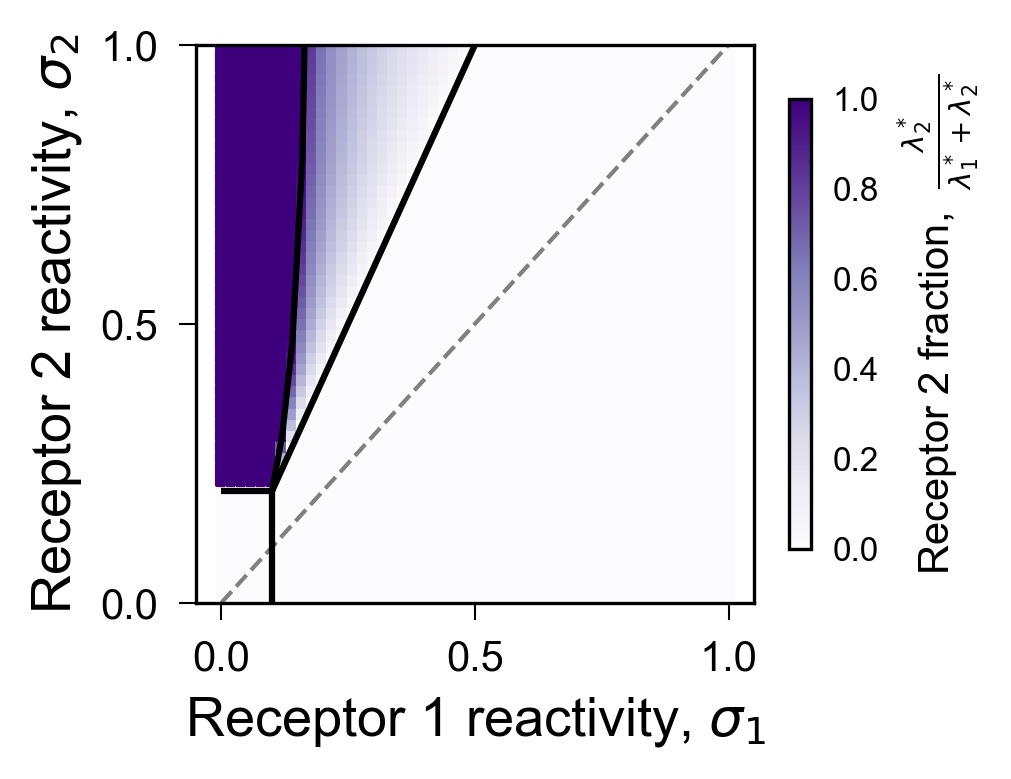

In [5]:
# Study impact of increasing receptor cross-reactivity
lam_opts = []
obj_opts = []
rec_num_opts = []
X_opts = []
avg_Sigmas = []
h1,h2 = 5.0, 5.0
sigmas = np.linspace(0,1, 51)
cross_sigmas = np.array(np.meshgrid(sigmas, sigmas)).T.reshape(-1,2)

for cs in cross_sigmas:

    Sigma = np.array([[cs[0], 0.0],[cs[0], cs[1]]])

    # Minimize harm
    res_harm = minimize(objective, args = (beta, Sigma, [h1, h2], np.ones(2), np.zeros(2)),
             x0 = np.ones(2).tolist(),
             tol=tol,
             constraints = LinearConstraint(np.eye(2), 0.0, np.inf))
        
    lam_opts.append(res_harm.x)
    obj_opts.append(res_harm.fun)
    rec_num_opts.append(np.sum(res_harm.x > tol))
    X_opts.append(Sigma.dot(res_harm.x))

# Show that conditions are satisfied
fig, ax1 = plt.subplots(1, 1, dpi = 150, figsize=(3, 2.6))
size = 5

im1 = ax1.scatter(cross_sigmas[:,0], cross_sigmas[:,1],
                 c = np.vstack(lam_opts)[:,1] /(np.vstack(lam_opts)[:,0] + np.vstack(lam_opts)[:,1])*((np.vstack(lam_opts)[:,0] + np.vstack(lam_opts)[:,1]) > tol),
                 cmap = 'Purples', marker = 's', norm = mpl.colors.Normalize(vmin = 0, vmax = 1),
                 s = size)

# ax1.axhline(y = beta/(n*h1), linestyle = '--', color = 'black', **kwargs)
feasible_thresh = sigmas*(n*h1 + n*h2)/(n*h1) >= beta/(n*h1)
ax1.plot(sigmas[feasible_thresh], (sigmas*(n*h1 + n*h2)/(n*h1))[feasible_thresh], linestyle = '-', color = 'black', linewidth = 1.5)
ax1.hlines(y = beta/(n*h1), xmin = 0.0, xmax = beta/(n*h1 + n*h2), linestyle = '-', color = 'black', linewidth = 1.5)
ax1.vlines(x=beta/(n*h1 + n*h2), ymin=0.0, ymax=beta/(n*h1), linestyle = '-', color = 'black', linewidth = 1.5)
ax1.plot(sigmas[(sigmas < beta/(n*h2))*feasible_thresh], sigmas[(sigmas < beta/(n*h2))*feasible_thresh]/(1 - n*h2*sigmas[(sigmas < beta/(n*h2))*feasible_thresh]/beta), 
         linestyle = '-', color = 'black', linewidth = 1.5)
ax1.plot(np.linspace(0,1,10), np.linspace(0,1,10), linestyle = '--', color = 'grey', zorder = 1)

ax1.set_ylim(0,1)
# ax1.set_title(r'two harmful microbes', fontsize = 10)
cb1 = fig.colorbar(im1, ax=ax1, orientation='vertical', shrink = 0.75, pad = 0.05)
cb1.set_label(r"Receptor 2 fraction,  $\frac{\lambda_2^*}{\lambda_1^* + \lambda_2^*}$" , fontsize = 10) #2\nrelative abundance, "+r'$\frac{\lambda_2^*}{\lambda_1^* + \lambda_2^*}$'
cb1.ax.tick_params(labelsize=8)
ax1.set_yticks([0.0, 1/2, 1])
ax1.set_xticks([0.0, 1/2, 1])
ax1.set_xlabel(r'Receptor 1 reactivity, $\sigma_1$', fontsize = 13)
ax1.set_ylabel(r'Receptor 2 reactivity, $\sigma_2$', fontsize = 13)
ax1.minorticks_off()
ax1.set_box_aspect(1)
ax1.tick_params(axis='x', top=False, direction = 'out')
ax1.tick_params(axis='y', right=False, direction = 'out')

fig.savefig('_figs/fig4_receptor-cross-2d'+'.pdf', dpi=300, bbox_inches='tight', transparent=True)

Fig 3: Phase diagram showing the regions of co-existence and mutual exclusion of two receptors as a function of their reactivities ($\sigma_1, \sigma_2$). As receptor 1 is cross-reactive while receptor 2 binds specifically, it tends to exclude receptor 2 which leads to a small region where receptor 2 is viable ($h_1g_1^\text{max}\beta^{-1} = h_1g_1^\text{max}\beta^{-1} = 5$).

Note: Can we estimate the area of the region of coexistence as a function of $h_1g_1^\text{max}\beta^{-1} = h_1g_1^\text{max}\beta^{-1} = 5$? Is it worth doing?

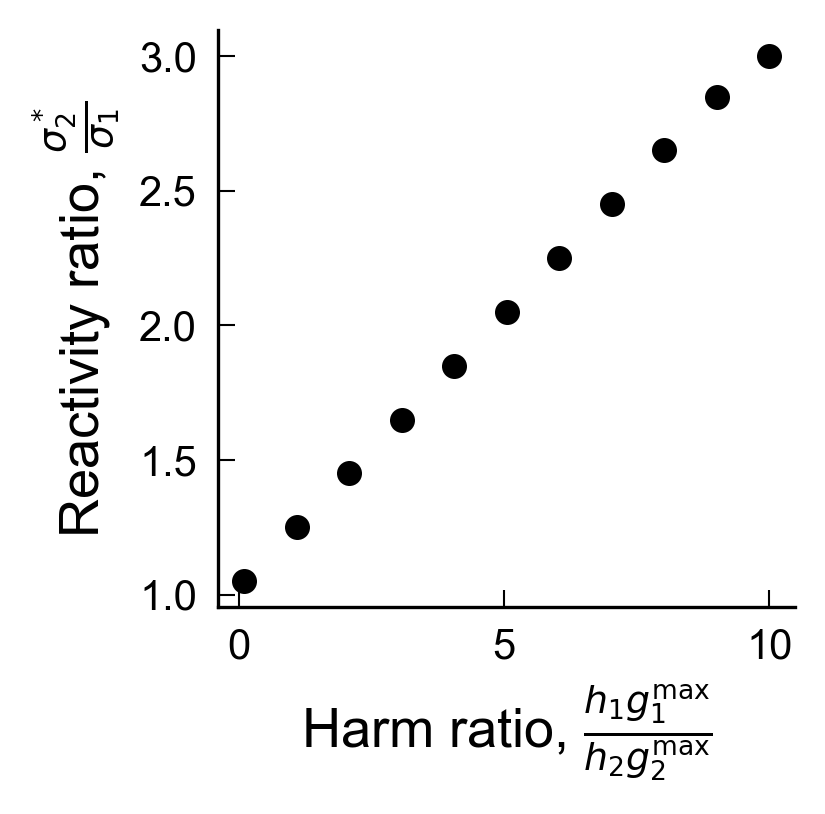

In [6]:
# For fixed receptor 1 cross-reactivity
# study impact of cost-benefit ratio of receptor 2 on the required specificity for this receptor
fig, ax1 = plt.subplots(1, 1, dpi = 150, figsize=(3, 2.5))
size = 50

sigma_2s = np.linspace(0,5, 201)
sigma_1 = 1/2
sigma_threshs = []
h2 = 5.0
hs = np.linspace(0.1, 10, 11)

for i, h1 in enumerate(hs):
    lam_opts = []
    obj_opts = []
    rec_num_opts = []
    X_opts = []
    avg_Sigmas = []
    for cs in sigma_2s:
    
        Sigma = np.array([[sigma_1, 0.0],[sigma_1, cs]])
    
        # Minimize harm
        res_harm = minimize(objective, args = (beta, Sigma, [h1, h2], np.ones(2), np.zeros(2)),
                 x0 = np.ones(2).tolist(),
                 tol=tol,
                 constraints = LinearConstraint(np.eye(2), 0.0, np.inf))
            
        lam_opts.append(res_harm.x)
        obj_opts.append(res_harm.fun)
        rec_num_opts.append(np.sum(res_harm.x > tol))
        X_opts.append(Sigma.dot(res_harm.x))

    arg_thresh = np.argmax(np.vstack(lam_opts)[:,1] > tol)
    sigma_threshs.append(sigma_2s[arg_thresh])
    
ax1.scatter(hs, np.array(sigma_threshs)/sigma_1, color = 'black')

# ax1.set_title(r'two microbes', fontsize = 10)
ax1.set_xlabel(r'Harm ratio, $\frac{h_1g_1^{\text{max}}}{h_2g_2^{\text{max}}}$', fontsize = 13)
ax1.set_ylabel(r'Reactivity ratio, $\frac{\sigma_2^*}{\sigma_1}$', fontsize = 13)
ax1.set_box_aspect(1)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.tick_params(top=False, right=False)
ax1.minorticks_off()
    
fig.savefig('_figs/SIfig4_receptor-threshold-2d'+'.pdf', dpi=300, bbox_inches='tight')

SI Figure: Reactivity of receptor 2 required for repertoire co-existence as a function of the harm-cost ratio ($h_1g_1^\text{max}\beta^{-1}$) for responding to microbe 1. As the potential harm from microbe 1 increases, threshold for including receptor 2 in the repertoire decreases ($\sigma_1 = 0.5$).

## Unstructured microbe-receptor interactions
For a community of $M$ microbes, construct a repertoire of $j \leq M$ receptors which randomly bind to a subset of microbes by targeting a single conserved gene, i.e. $\sigma_{\mu,j} \sim \text{Bernoulli}(p)$. What should the optimal repertoire be? How does it change with cluster number?

#### Effect of cross-reactivity, $p$

In [7]:
lam_opts = []
obj_opts = []
rec_num_opts = []
X_opts = []
obj_X_dist = []
obj_minimizer_dist = []
rec_cov_dist = []
simpson_index_list = []
opt_sigma_std_list = []


m, k = 10, 20
runs = 1000
ps = np.logspace(np.log10(1/m), 0, 21)

for i, p in enumerate(ps):
    obj_min, obj_minimizer_cumul, obj_minimizer, obj_rec_num, X, obj_X_ratio, rec_cov, simpson_index, opt_sigma_std = 0.0, 0.0, [], 0.0, 0.0, [], [], 0.0, 0.0
    for r in np.arange(0,runs):
        Sigma = np.unique(np.random.binomial(1, p, size = (m,k)).dot(np.diag(np.random.uniform(low=0.0, high=1.0, size=k))), axis = 1)
        res_harm = minimize(objective, args = (1/k, Sigma, np.ones(m), np.ones(m), np.zeros(m)),
                 x0 = np.ones(Sigma.shape[1]).tolist(),
                 tol=tol,
                 constraints = LinearConstraint(np.eye(Sigma.shape[1]), 0.0, np.inf))
        obj_min += res_harm.fun
        obj_minimizer_cumul += np.sum(res_harm.x)
        obj_minimizer += (res_harm.x).tolist()
        obj_X_ratio += (Sigma.dot(np.maximum(res_harm.x,0))/np.sum(np.maximum(res_harm.x,0))).tolist()
        rec_cov += np.sum(np.diag(np.ones(m)).dot(Sigma), axis = 0).tolist()
        obj_rec_num += np.sum(res_harm.x > tol)
        X += Sigma.dot(np.maximum(res_harm.x,0))
        opt_sigma_std += np.mean(np.sum(Sigma[:,res_harm.x > tol] > tol, axis = 1)/k)
        simpson_index += 1 - np.sum(np.maximum(res_harm.x, 0)*(np.maximum(res_harm.x, 0) -1))/(np.sum(np.maximum(res_harm.x, 0))*(np.sum(np.maximum(res_harm.x, 0)) -1))
        
    lam_opts.append(obj_minimizer_cumul/runs)
    obj_opts.append(obj_min/runs)
    obj_minimizer_dist.append(obj_minimizer)
    obj_X_dist.append(obj_X_ratio)
    rec_cov_dist.append(rec_cov)
    rec_num_opts.append(obj_rec_num/runs)
    X_opts.append(X/runs)
    simpson_index_list.append(simpson_index/runs)
    opt_sigma_std_list.append(opt_sigma_std/runs)

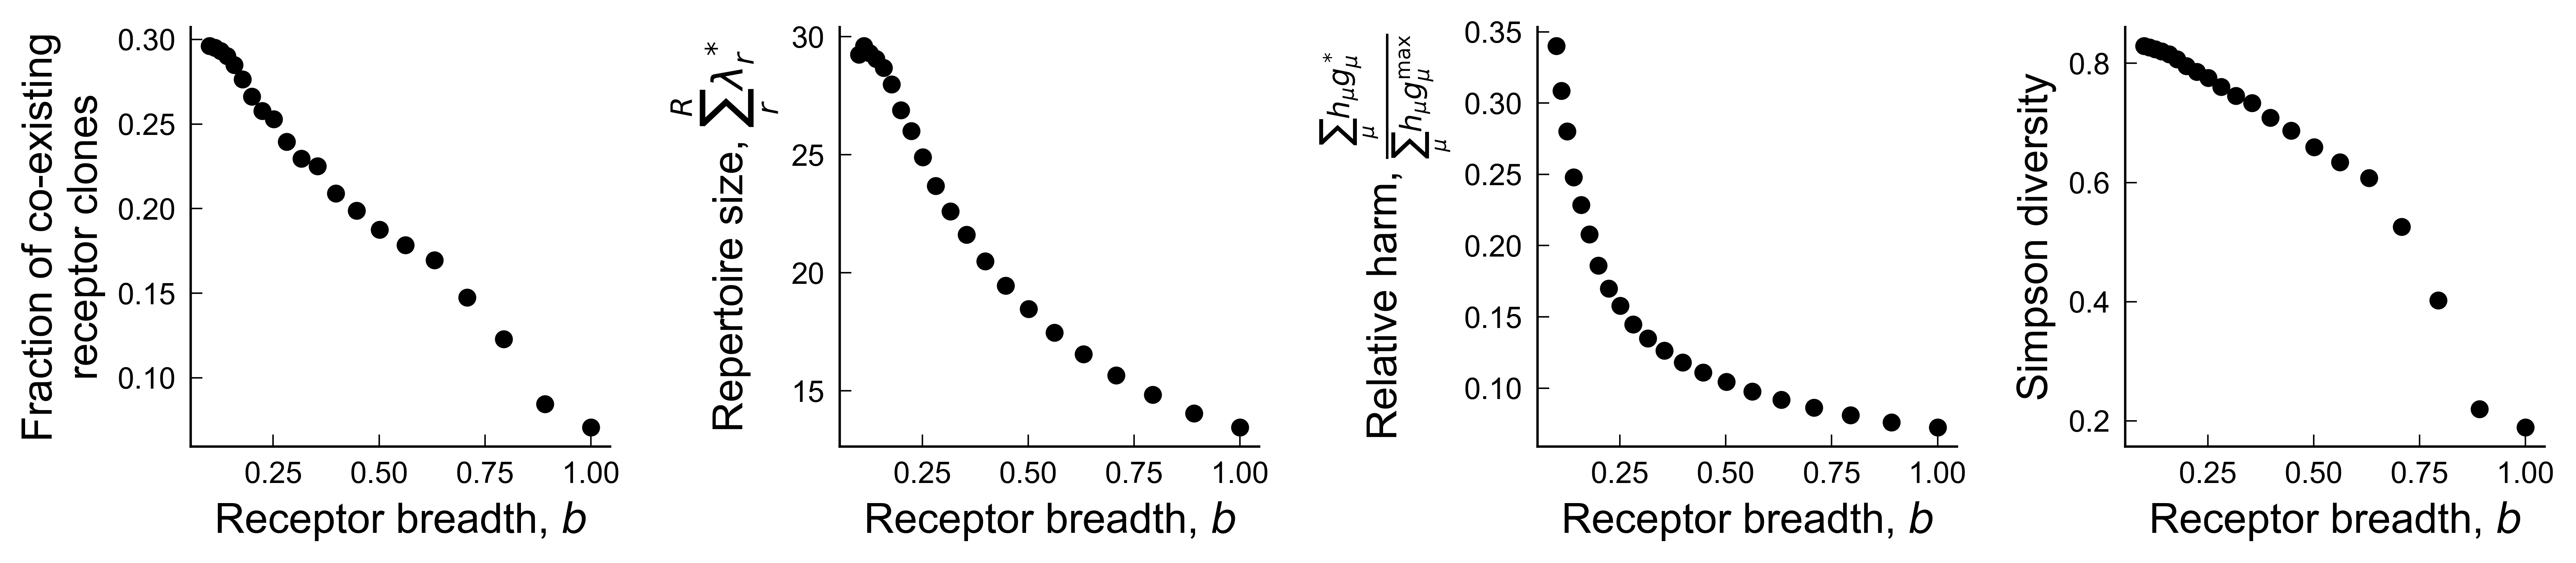

In [8]:
# Plot numerical values and analytic values verus beta
fig, axs = plt.subplots(1, 4, dpi = 300, figsize=(12, 2.5), layout='constrained')

axs[0].scatter(ps, np.array(rec_num_opts)/k, color = 'k')
# axs[0].plot([1.0,m], [1.0,m], 'k--')
axs[0].set_xlabel(r'Receptor breadth, $b$', fontsize = 14)
axs[0].set_ylabel('Fraction of co-existing\nreceptor clones', fontsize = 14)

axs[1].scatter(ps, lam_opts, color = 'k')
axs[1].set_xlabel(r'Receptor breadth, $b$', fontsize = 14)
axs[1].set_ylabel('Repertoire size, '+r'$\sum_r^R \lambda_r^*$', fontsize = 14)

axs[2].scatter(ps, (np.array(obj_opts) - 1/k*np.array(lam_opts))/m, color = 'k')
axs[2].set_xlabel(r'Receptor breadth, $b$', fontsize = 14)
axs[2].set_ylabel(r'Relative harm, $\frac{\sum_\mu h_\mu g_\mu^*}{\sum_\mu h_\mu g_\mu^\text{max}}$', fontsize = 14)

axs[3].scatter(ps, simpson_index_list, color = 'k')
axs[3].set_xlabel(r'Receptor breadth, $b$', fontsize = 14)
axs[3].set_ylabel(r'Simpson diversity', fontsize = 14)

for j, ax in enumerate(axs.flat):
    # ax.semilogx()
    ax.xaxis.set_tick_params(labelbottom=True)
    ax.yaxis.set_tick_params(labelleft=True)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(top=False, right=False)
    ax.minorticks_off()
    ax.set_box_aspect(1)

fig.savefig('_figs/fig_many_receptors_cross_reactivity'+'.pdf', dpi=300, bbox_inches='tight')

(A) Figure 3: Fraction of clones selected into the repertoire is a decreasing function of repertoire cross-reactivity. Starting from low cross-reactivity ($p = 1/R$), only a small fraction of the available repertoire is utilized ($R = 20, K = 10$). The curve is generated by drawing a reactivity matrix for microbes and receptors from a distribution parameterized by a single parameter $p$, and computing the optimal immune coverage.

(B) SI Figure: Total number of receptors selected into the repertoire is a decreasing function of repertoire cross-reactivity.

(C) SI Figure: Optimal harm incurred is a decreasing function of repertoire cross-reactivity. A more cross-reactive repertoire can more efficiently minimize harm

(D) SI Figure: Diversity of the selected repertoire is a decreasing function of repertoire cross-reactivity. Diversity is measured using the simpson diversity index. The fact that it stays fairly high is because each receptor is drawn from the same distribution.

## Ecological interactions

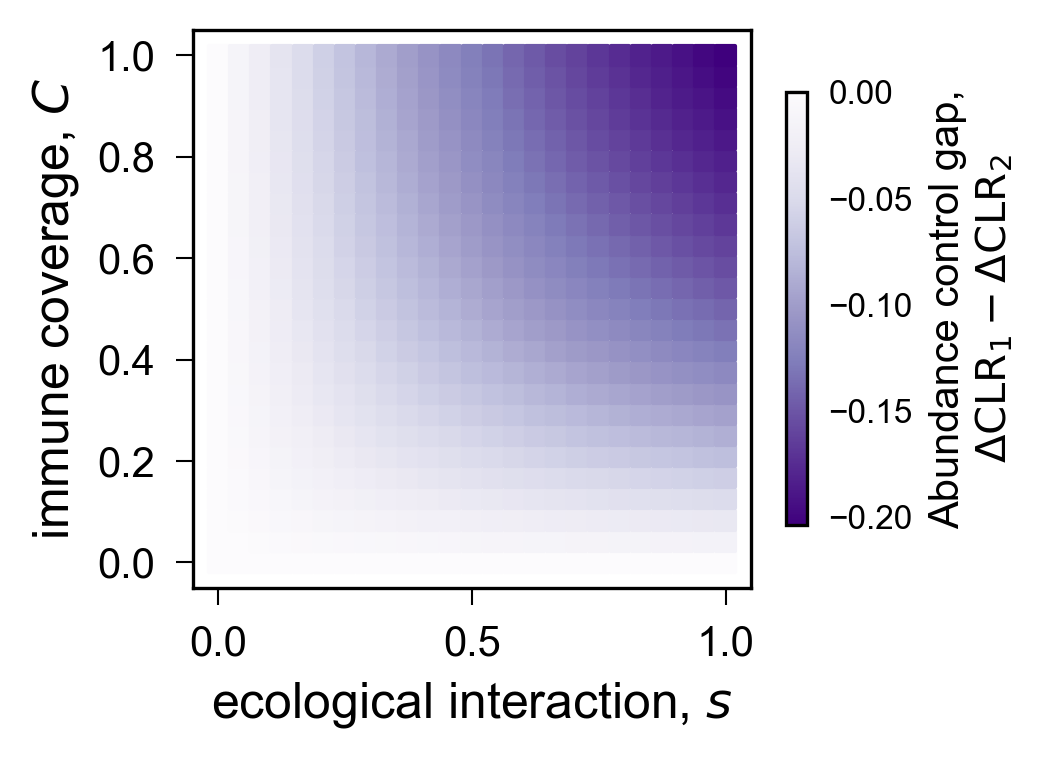

In [9]:
# Study impact of increasing receptor cross-reactivity
outs = []
params = np.linspace(0,1, 25)
cross_params = np.array(np.meshgrid(params, params)).T.reshape(-1,2)

for ps in cross_params:

    # compute abundance gap
    g1s = 1/(1 + ps[1])
    g2s = 1/(1 + ps[1] + ps[0]*1/(1 + ps[1]))
    g1s_zeroC = 1.0
    g2s_zeroC = 1/(1 + ps[0])
    out = np.log10((g1s/g1s_zeroC)/(g2s/g2s_zeroC))
    outs.append(out)

    # # Compute derivative
    # out = (ps[0]/(1 + ps[1])**2 - 1)/(1 + ps[1] + ps[0]/(1 + ps[1]))**2
    # outs.append(out)

# Show that conditions are satisfied
fig, ax1 = plt.subplots(1, 1, dpi = 150, figsize=(3, 2.5))
size = 20

im1 = ax1.scatter(cross_params[:,0], cross_params[:,1],
                 c = np.vstack(outs),
                 cmap = 'Purples_r', marker = 's', norm = mpl.colors.Normalize(vmin = -np.amax(np.abs(outs)), vmax = 0*np.amax(np.abs(outs))),
                 s = size)

# boundary = np.sqrt(cross_params[:,0]) - 1
# ax1.plot(cross_params[:,0][boundary >= 0], boundary[boundary >= 0], '-', color = 'black')

# ax1.set_ylim(0,1)
cb1 = fig.colorbar(im1, ax=ax1, orientation='vertical', shrink = 0.75, pad = 0.05)
cb1.set_label('Abundance control gap,\n'+r'$\Delta\text{CLR}_{1} - \Delta\text{CLR}_{2}$', fontsize = 10) #"response, "+r'$\frac{\partial\tilde{g}_1}{\partial C}$'
cb1.ax.tick_params(labelsize=8)
ax1.set_xlabel('ecological interaction, '+ r'$s$', fontsize = 12)
ax1.set_ylabel('immune coverage, '+ r'$C$', fontsize = 12)
ax1.minorticks_off()
ax1.tick_params(axis='x', top=False, direction = 'out')
ax1.tick_params(axis='y', right=False, direction = 'out')
ax1.set_box_aspect(1)

fig.savefig('_figs/fig_derivative_eco_imm'+'.pdf', dpi=300, bbox_inches='tight')

Fig SI: Abundance response of a microbe as a function of immune coverage and ecological interactions. For sufficiently strong competitive ecological interactions, immune coverage can increase the abundance of a microbe.

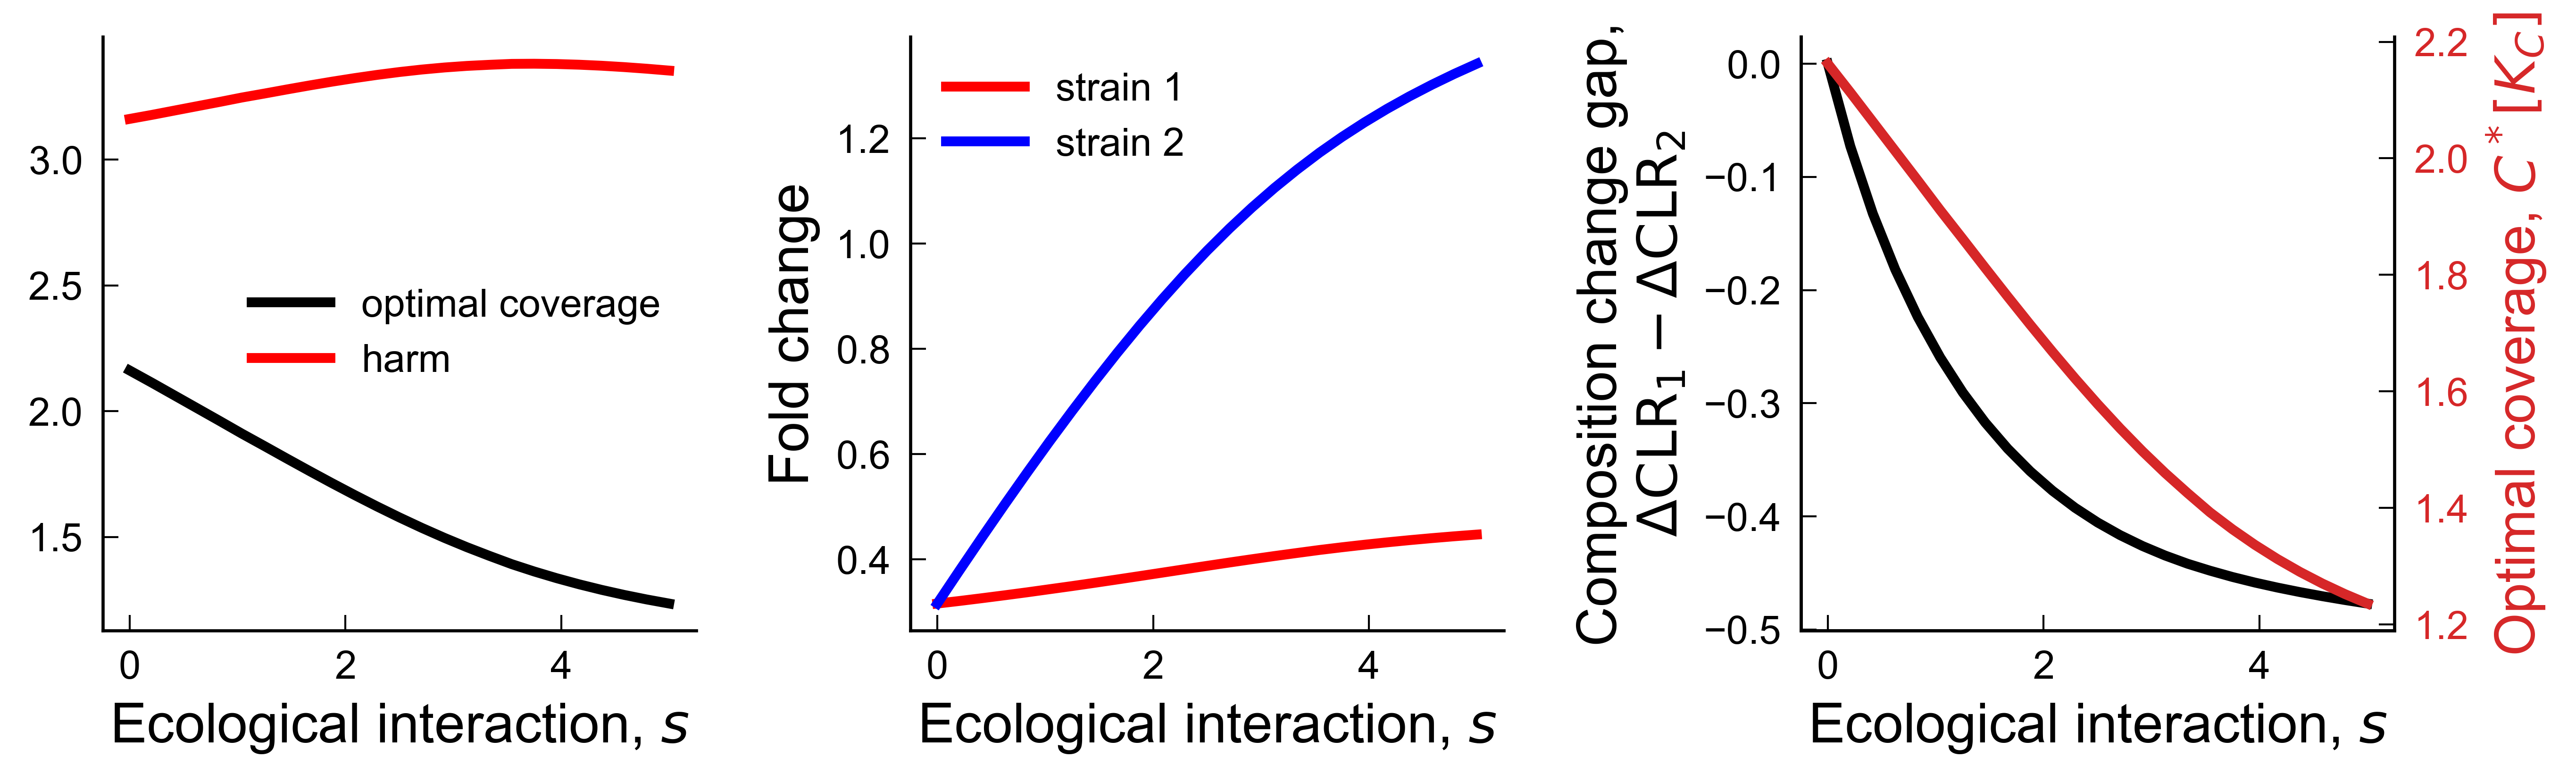

In [10]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, dpi = 300, figsize=(9, 2.65), layout='constrained')

ss = np.linspace(0, 5.0, 25)
C_opts = []
obj_opts = []
hs = 5*np.ones(2)

for i, p in enumerate(ss):

    res = minimize(limited_ecology, args = (1.0, 1.0, hs, np.ones(2), p),
                 x0 = [1.0],
                 tol=tol,
                 constraints = LinearConstraint([1.0], 0.0, np.inf))

    C_opts.append(res.x.item())
    obj_opts.append(res.fun)

# ax1.scatter(p, res.x, c= 'black', label = "numeric" if i == 0 else '')
g1s = 1/(1 + np.array(C_opts))
g2s = 1/(1 + np.array(C_opts) + ss*1/(1 + np.array(C_opts)))
g1s_zeroC = 1
g2s_zeroC = 1/(1 + ss)

ax1.plot(ss, C_opts, 'k', label = 'optimal coverage', **kwargs)
ax1.plot(ss, np.array(obj_opts) - np.array(C_opts), 'red', label = 'harm', **kwargs)
ax1.legend()

ax2.plot(ss, g1s/g1s_zeroC, color = 'red', label = 'strain 1', **kwargs)
ax2.plot(ss, g2s/g2s_zeroC, color = 'blue', label = 'strain 2', **kwargs)
ax2.set_ylabel(r'Fold change', fontsize = 14)
ax2.legend()

ax3.plot(ss, np.log10((g1s/g1s_zeroC)/(g2s/g2s_zeroC)), color = 'k', **kwargs)
axtwin = ax3.twinx()
axtwin.tick_params(axis='y', labelcolor='tab:red')
axtwin.set_ylabel(r'Optimal coverage, $C^* [K_C]$', color='tab:red', fontsize = 14)
axtwin.minorticks_off()
axtwin.tick_params(axis='both', which='major', labelsize=10)
axtwin.xaxis.set_tick_params(labeltop=False)

axtwin.plot(ss, C_opts,
              color = 'tab:red',zorder = 0, **kwargs)
axtwin.spines['top'].set_visible(False)

ax3.set_ylabel('Composition change gap,\n'+r'$\Delta\text{CLR}_{1} - \Delta\text{CLR}_{2}$', fontsize = 14)

for ax in (ax1, ax2, ax3):
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(top=False, right=False)
    ax.set_xlabel(r'Ecological interaction, $s$', fontsize = 14)

fig.savefig('_figs/fig_ctrl_gap_eco_imm'+'.pdf', dpi=300, bbox_inches='tight')

Fig 5: Difference in abundance response to immune coverage of ecologically interacting microbes. The interaction dampens the effect of immune coverage on the microbes.

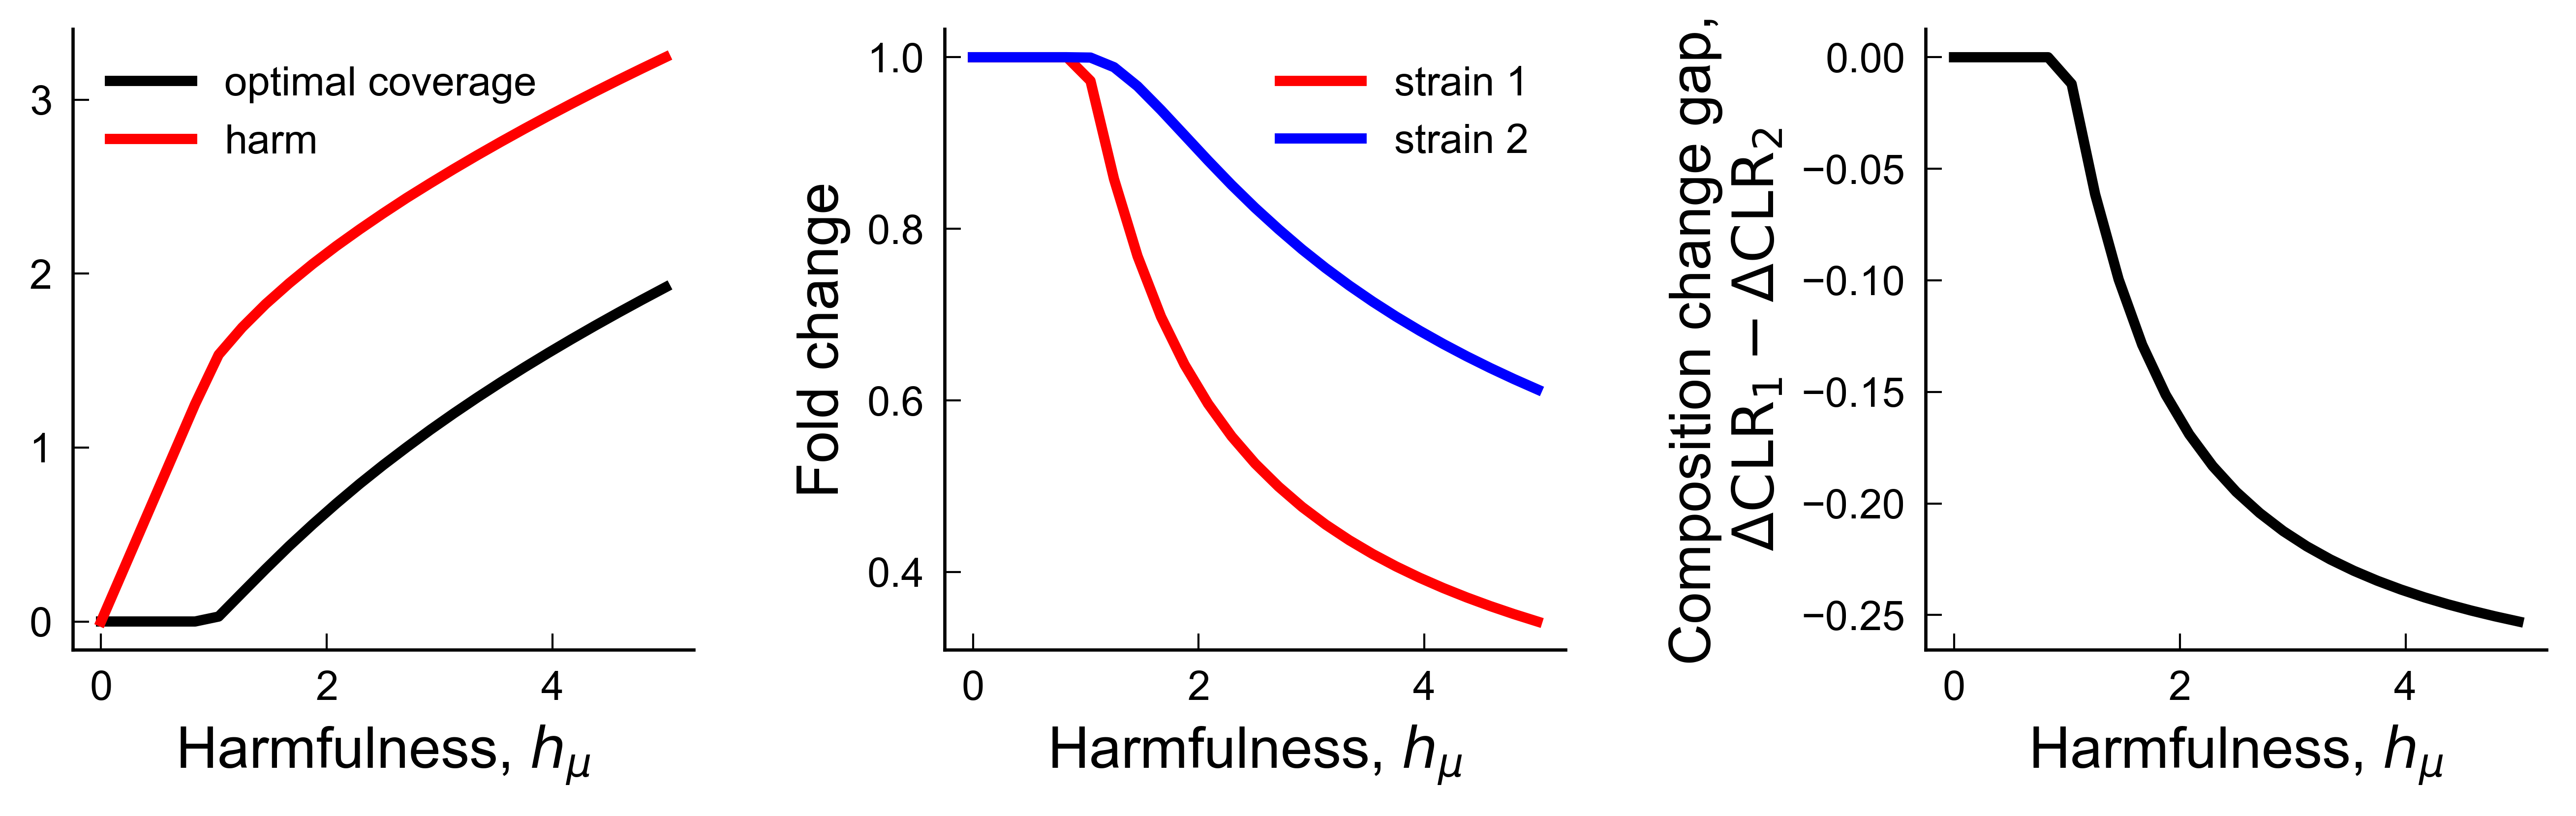

In [11]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, dpi = 300, figsize=(9, 2.65), layout='constrained')

ps = np.linspace(0, 5.0, 25)
C_opts = []
obj_opts = []
hs = 5*np.ones(2)

for i, p in enumerate(ps):

    res = minimize(limited_ecology, args = (1.0, 1.0, p*np.ones(2), np.ones(2), 1.0),
                 x0 = [1.0],
                 tol=tol,
                 constraints = LinearConstraint([1.0], 0.0, np.inf))

    C_opts.append(res.x.item())
    obj_opts.append(res.fun)

# ax1.scatter(p, res.x, c= 'black', label = "numeric" if i == 0 else '')
g1s = 1/(1 + np.array(C_opts))
g2s = 1/(1 + np.array(C_opts) + 1/(1 + np.array(C_opts)))
g1s_zeroC = 1
g2s_zeroC = 1/(1 + 1)

ax1.plot(ps, C_opts, 'k', label = 'optimal coverage', **kwargs)
ax1.plot(ps, np.array(obj_opts) - np.array(C_opts), 'red', label = 'harm', **kwargs)
ax1.legend()

ax2.plot(ps, g1s/g1s_zeroC, color = 'red', label = 'strain 1', **kwargs)
ax2.plot(ps, g2s/g2s_zeroC, color = 'blue', label = 'strain 2', **kwargs)
ax2.set_ylabel(r'Fold change', fontsize = 14)
ax2.legend()

ax3.plot(ps, np.log10((g1s/g1s_zeroC)/(g2s/g2s_zeroC)), color = 'k', **kwargs)
ax3.set_ylabel('Composition change gap,\n'+r'$\Delta\text{CLR}_{1} - \Delta\text{CLR}_{2}$', fontsize = 14)

for ax in (ax1, ax2, ax3):
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(top=False, right=False)
    ax.set_xlabel(r'Harmfulness, $h_\mu$', fontsize = 14)

fig.savefig('_figs/fig_ctrl_gap_eco_imm_vary_hs'+'.pdf', dpi=300, bbox_inches='tight')